# Pregunta 1: MRI de rodilla

Comparación factorial de CNN propia/ResNet-50, BCE/focal y dos estrategias de confianza. Este cuaderno consulta exclusivamente las salidas persistidas y auditadas. Los controles de entrenamiento permanecen desactivados.


## Configuración y decisiones previas

Semilla 42, hasta 50 épocas y paciencia 10. Los resultados científicos y smoke usan directorios diferentes. Para ejecución completa se recomienda el comando del README.


In [1]:
from pathlib import Path
import os
import pandas as pd
from IPython.display import display, Image
from neural_exam.config import load_settings, PROJECT_ROOT
from neural_exam.cli import doctor
from neural_exam.common.io import read_json
from neural_exam.common.locking import execution_lock
from neural_exam.mri.data import prepare
from neural_exam.mri.pipeline import run
from neural_exam.reporting import prepare_report_assets

RUN_PREPARE = False
RUN_TRAINING = False
RESUME = False
GENERATE_REPORT_ASSETS = False
os.environ.setdefault('OUTPUT_DIR', '/outputs' if Path('/outputs').is_dir() else 'E:/Kaggle/exam-output-mri/stratified-v2')
settings = load_settings(PROJECT_ROOT / 'configs/mri.toml')
task = 'mri'
output = settings.output_root / task


## Diagnóstico sin operaciones GPU

La comprobación CUDA se realizará por separado mediante doctor --gpu-check. Esta celda consulta versiones y rutas.


In [2]:
diagnostics = doctor(settings, gpu_check=False)
display(pd.DataFrame(list(diagnostics['dependencies'].items()), columns=['dependency', 'version']))
runtime = read_json(settings.output_root / 'audit/mri_runtime.json')
display(pd.DataFrame(runtime['checks']))


,dependency,version
0,torch,2.10.0+cu128
1,torchvision,0.25.0+cu128
2,ultralytics,8.4.21
3,pydicom,3.0.1
4,rasterio,1.4.3
5,scikit-learn,1.9.1


,architecture,loss,loss_finite,gradients_finite,shape,peak_cuda_memory_bytes
0,scratch,bce,True,True,"[4, 12]",1146300416
1,scratch,focal,True,True,"[4, 12]",1147348992
2,resnet50,bce,True,True,"[4, 12]",1664894464
3,resnet50,focal,True,True,"[4, 12]",1664894464


## Integridad y preparación

Los mismos 58 expertos se evaluaron en la ejecución inicial y en la partición corregida. La corrección empleó exclusivamente etiquetas débiles; esta cohorte no es una nueva prueba externa nunca consultada. El léxico, el umbral y los hiperparámetros permanecieron fijados. La auditoría compara bytes de la caché con originales, valida identificadores y evita compartir estudios entre particiones. Los identificadores anonimizados no prueban independencia de pacientes reales.


In [3]:
if RUN_PREPARE:
    with execution_lock(settings.output_root):
        manifest = prepare(settings)
else:
    manifest = read_json(output / 'manifest.json')
audit = read_json(settings.output_root / 'audit/mri_data.json')
display({key: audit[key] for key in ['all_metadata_studies', 'all_metadata_series', 'selected_dicom_files',
                                    'docker_cache_byte_matches', 'split_counts', 'patient_split_overlaps']})


{'all_metadata_studies': 4407,
 'all_metadata_series': 24371,
 'selected_dicom_files': 22954,
 'docker_cache_byte_matches': True,
 'split_counts': {'gold': 58, 'val': 108, 'train': 434},
 'patient_split_overlaps': []}

## Inventario de particiones

Los conteos provienen del manifiesto real; no se usan números simulados.


In [4]:
display(pd.DataFrame(list(manifest['split_counts'].items()), columns=['partition', 'studies']))
display(pd.read_csv(output / 'class_balance.csv'))
display(pd.DataFrame({'script': list(audit['weak_reports_by_script']),
                      'weak_reports': list(audit['weak_reports_by_script'].values()),
                      'supported': [audit['weak_supported_by_script'].get(key, 0) for key in audit['weak_reports_by_script']]}))


,partition,studies
0,gold,58
1,val,108
2,train,434


,label,train,val,gold,high_observed,high_positive
0,ACL,143,42,24,226,143
1,MCL,102,39,9,189,102
2,Medial Meniscus,158,47,26,222,158
3,Lateral Meniscus,127,41,23,233,127
4,Medial OA,35,12,15,51,35
5,Lateral OA,10,4,11,36,10
6,PF OA,45,18,21,123,45
7,Effusion,282,77,35,318,282
8,Synovitis,140,41,27,140,140
9,Baker's,145,43,12,206,145


,script,weak_reports,supported
0,Latin/mixed,3811,3488
1,Cyrillic,217,209
2,Greek,318,239
3,Thai,3,3


## Experimentos

Esta celda importa la implementación del paquete. No duplica arquitectura, entrenamiento o evaluación. No ejecutar simultáneamente con otros entrenamientos.


In [5]:
if RUN_TRAINING:
    with execution_lock(settings.output_root):
        display(run(settings, resume=RESUME, quick=False, manifest=manifest))
else:
    print('RUN_TRAINING=False: se leen resultados existentes, sin repetir entrenamientos.')


RUN_TRAINING=False: se leen resultados existentes, sin repetir entrenamientos.


## Evaluación y revisión

Revisar AUC por etiqueta, cobertura de reglas y Grad-CAM para LCA, menisco medial y derrame.

No elegir hiperparámetros por rendimiento de prueba. Una métrica ND debe conservarse como indefinida.


In [6]:
result_audit = read_json(settings.output_root / 'audit/mri_results.json')
assert result_audit['status'] == 'passed'
display(pd.DataFrame(result_audit['experiments']).drop(columns=['checkpoint_sha256']))
scores = pd.read_csv(output / 'metrics_all_labels.csv')
display(scores.pivot(index='label', columns='experiment', values='auc'))
display(scores[scores['experiment'] == 'scratch_bce_weighted'])
agreement = pd.DataFrame(read_json(output / 'label_agreement.json')['per_label'])
agreement['coverage_of_58'] = agreement['observed'] / 58
display(agreement)


,experiment,epochs,best_epoch,macro_auc,partial_macro_auc,auc_labels_defined,macro_f1
0,scratch_bce_weighted,48,38,0.577643,0.577643,12,0.360975
1,scratch_bce_high_confidence,23,13,0.512970,0.512970,12,0.453527
2,scratch_focal_weighted,29,19,0.572324,0.572324,12,0.496078
3,scratch_focal_high_confidence,23,13,0.520409,0.520409,12,0.425347
4,resnet50_bce_weighted,12,2,0.618908,0.618908,12,0.361449
5,resnet50_bce_high_confidence,11,1,0.602022,0.602022,12,0.451297
6,resnet50_focal_weighted,12,2,0.619868,0.619868,12,0.505577
7,resnet50_focal_high_confidence,12,2,0.587737,0.587737,12,0.486337


experiment,resnet50_bce_high_confidence,resnet50_bce_weighted,resnet50_focal_high_confidence,resnet50_focal_weighted,scratch_bce_high_confidence,scratch_bce_weighted,scratch_focal_high_confidence,scratch_focal_weighted
label,,,,,,,,
ACL,0.604167,0.726716,0.561275,0.618873,0.448529,0.677696,0.405637,0.616422
Baker's,0.721014,0.617754,0.628623,0.659420,0.530797,0.523551,0.559783,0.545290
Contusion,0.530364,0.753036,0.682861,0.696356,0.542510,0.616734,0.554656,0.619433
Effusion,0.767702,0.731677,0.730435,0.816149,0.503106,0.547826,0.581366,0.531677
Fracture,0.488889,0.495833,0.412500,0.494444,0.502778,0.468056,0.495833,0.475000
Lateral Meniscus,0.509317,0.489441,0.629814,0.581366,0.458385,0.434783,0.465839,0.453416
Lateral OA,0.342360,0.682785,0.510638,0.644101,0.431335,0.733075,0.450677,0.647969
MCL,0.530612,0.562358,0.528345,0.555556,0.544218,0.564626,0.571429,0.575964
Medial Meniscus,0.657452,0.484375,0.534856,0.509615,0.521635,0.538462,0.474760,0.551683


,experiment,label,support,positives,auc,precision,recall,f1
0,scratch_bce_weighted,ACL,58,24,0.677696,0.500000,0.750000,0.600000
1,scratch_bce_weighted,MCL,58,9,0.564626,0.166667,0.555556,0.256410
2,scratch_bce_weighted,Medial Meniscus,58,26,0.538462,0.418182,0.884615,0.567901
3,scratch_bce_weighted,Lateral Meniscus,58,23,0.434783,0.285714,0.086957,0.133333
4,scratch_bce_weighted,Medial OA,58,15,0.660465,1.000000,0.066667,0.125000
5,scratch_bce_weighted,Lateral OA,58,11,0.733075,0.000000,0.000000,0.000000
6,scratch_bce_weighted,PF OA,58,21,0.671815,1.000000,0.047619,0.090909
7,scratch_bce_weighted,Effusion,58,35,0.547826,0.603448,1.000000,0.752688
8,scratch_bce_weighted,Synovitis,58,27,0.494624,0.469388,0.851852,0.605263
9,scratch_bce_weighted,Baker's,58,12,0.523551,0.243243,0.750000,0.367347


,label,minimum_confidence,observed,agreement,estimated_disagreement,coverage_of_58
0,ACL,0.0,50,0.840000,0.160000,0.862069
1,ACL,0.8,28,0.928571,0.071429,0.482759
2,MCL,0.0,53,0.924528,0.075472,0.913793
3,MCL,0.8,21,0.857143,0.142857,0.362069
4,Medial Meniscus,0.0,54,0.629630,0.370370,0.931034
5,Medial Meniscus,0.8,21,0.809524,0.190476,0.362069
6,Lateral Meniscus,0.0,52,0.711538,0.288462,0.896552
7,Lateral Meniscus,0.8,16,0.875000,0.125000,0.275862
8,Medial OA,0.0,54,0.759259,0.240741,0.931034
9,Medial OA,0.8,5,0.800000,0.200000,0.086207


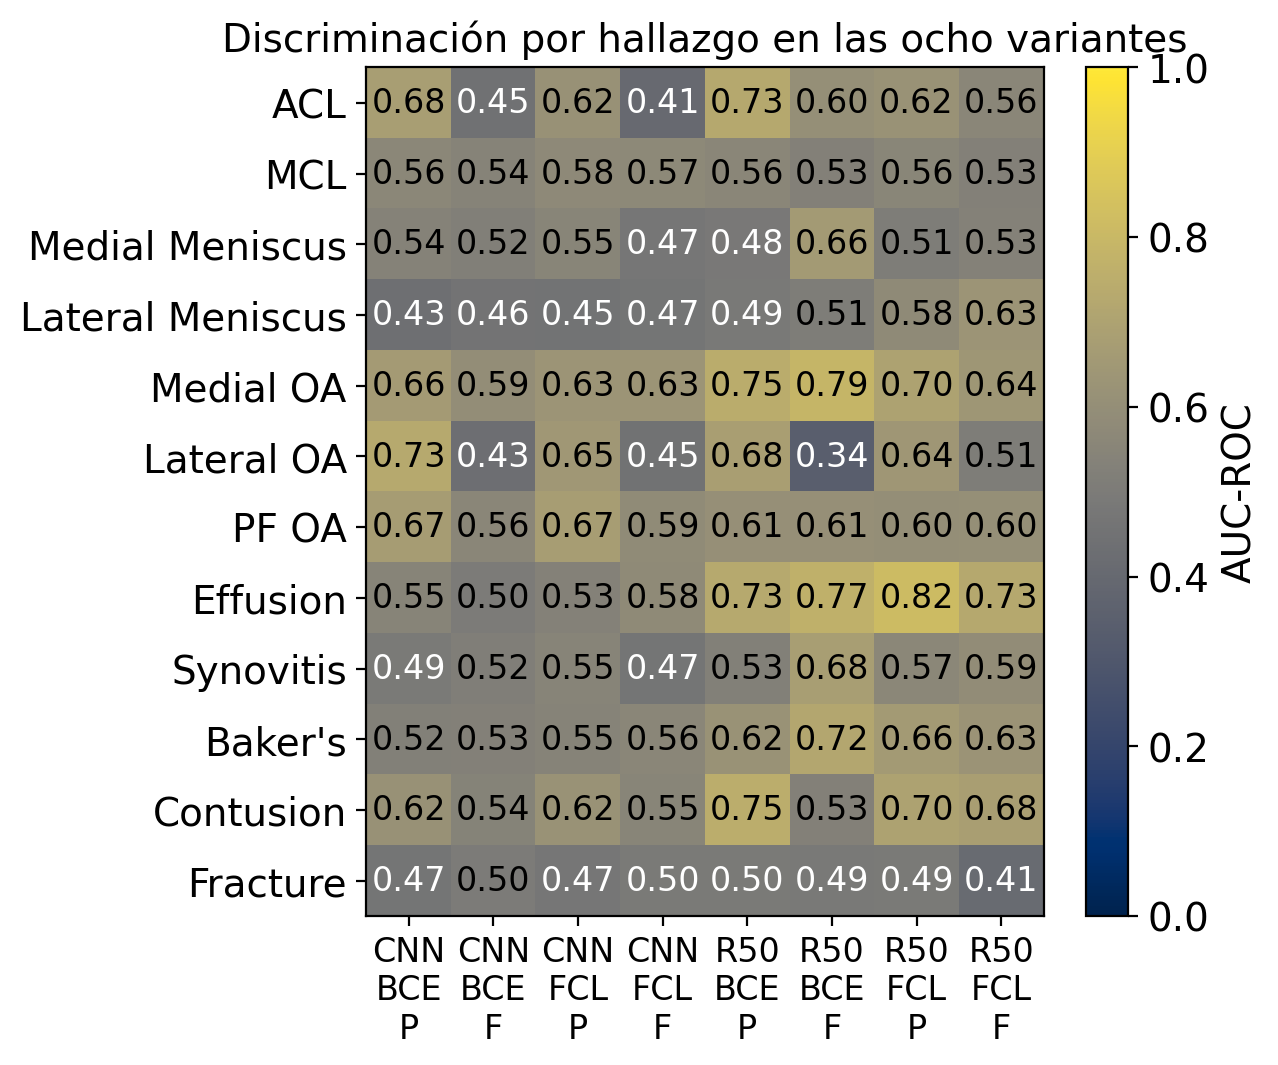

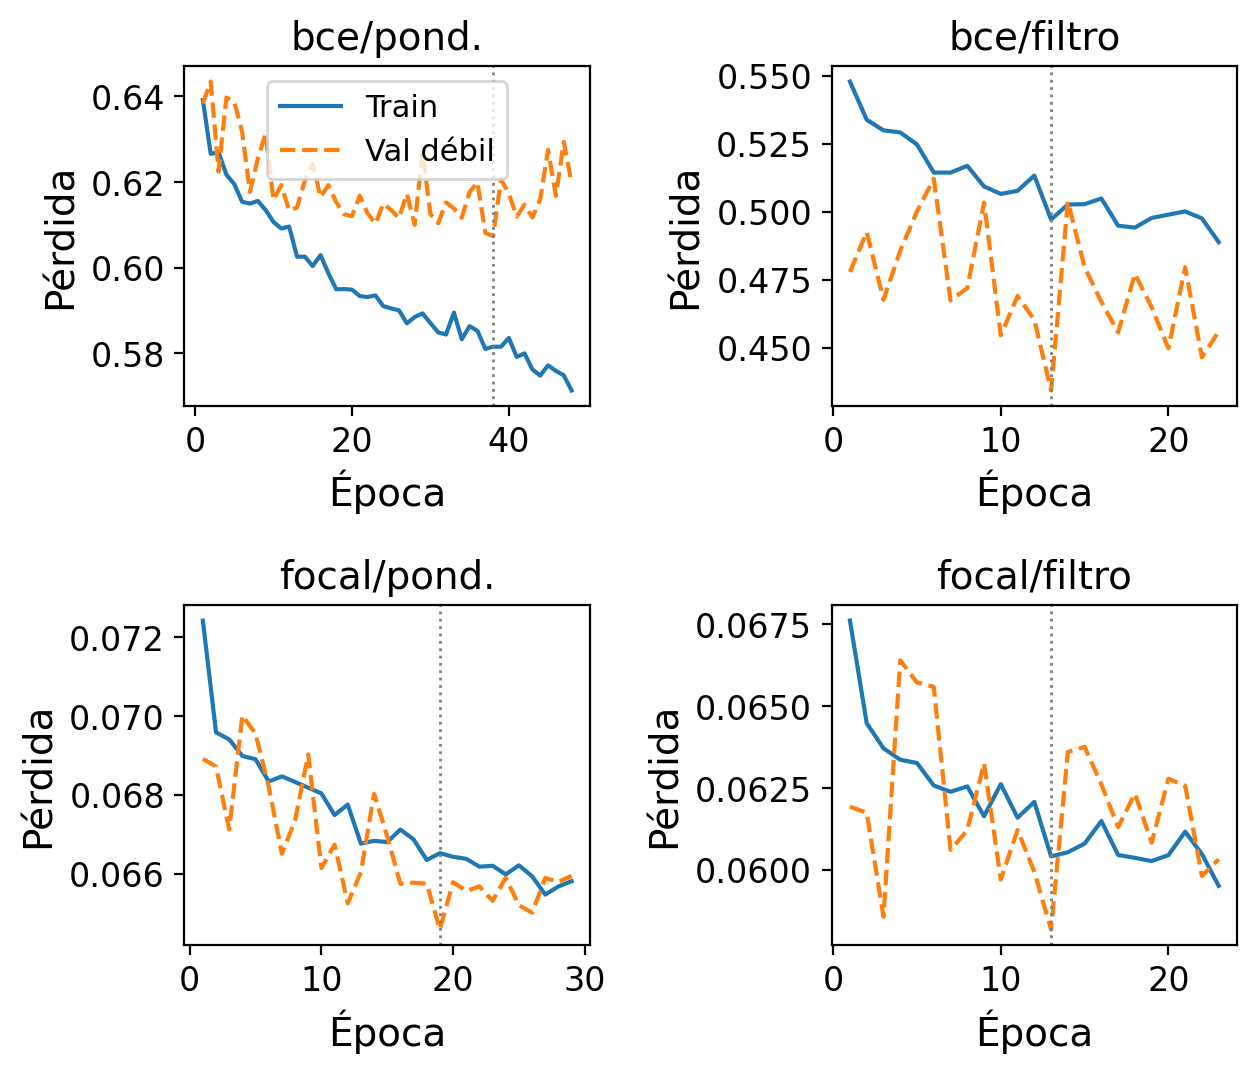

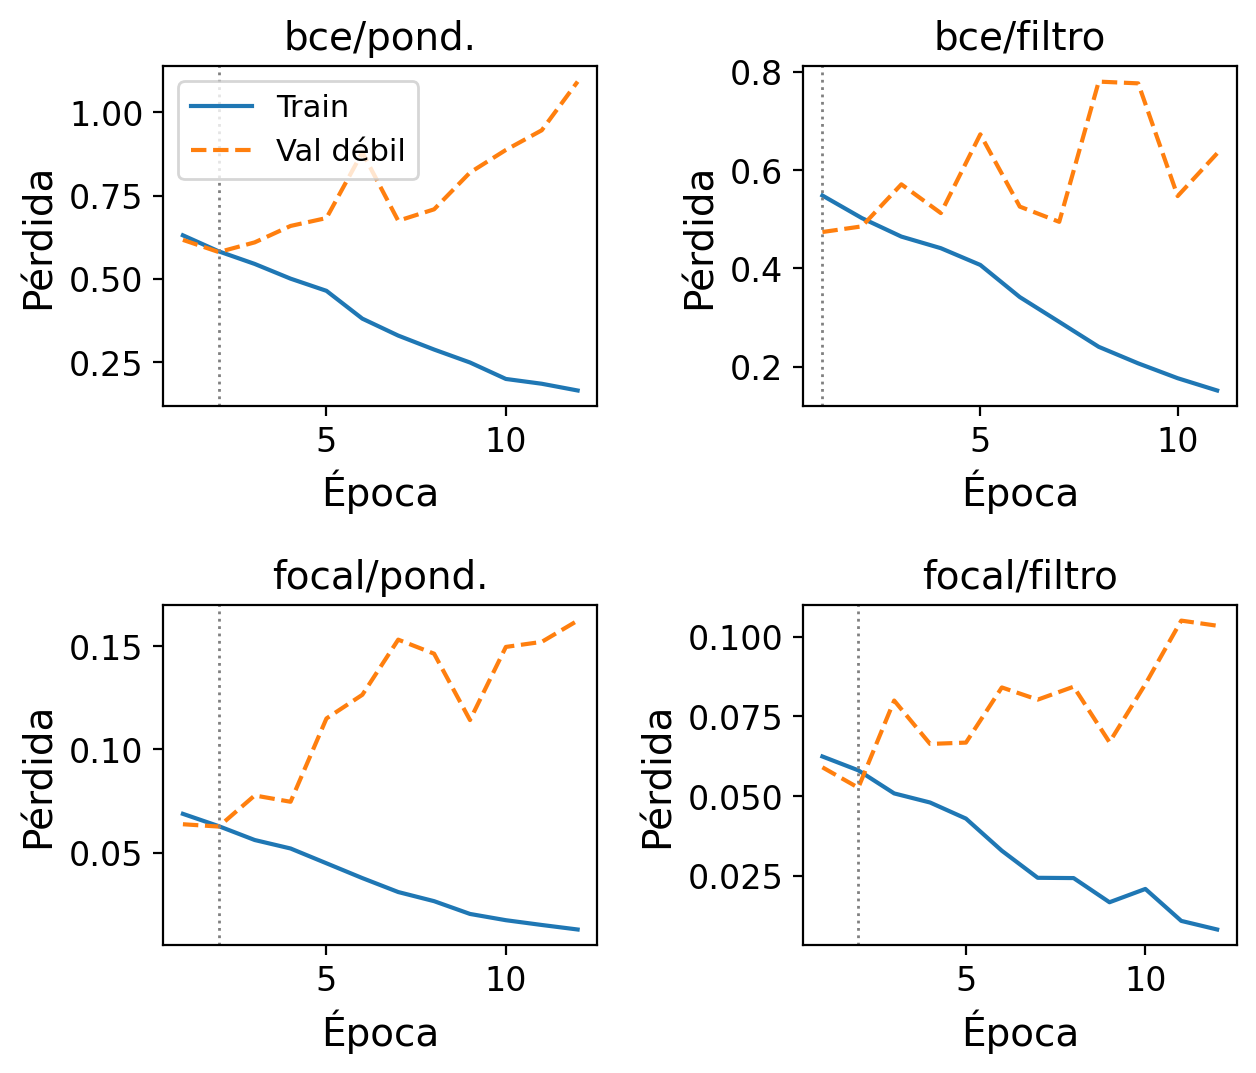

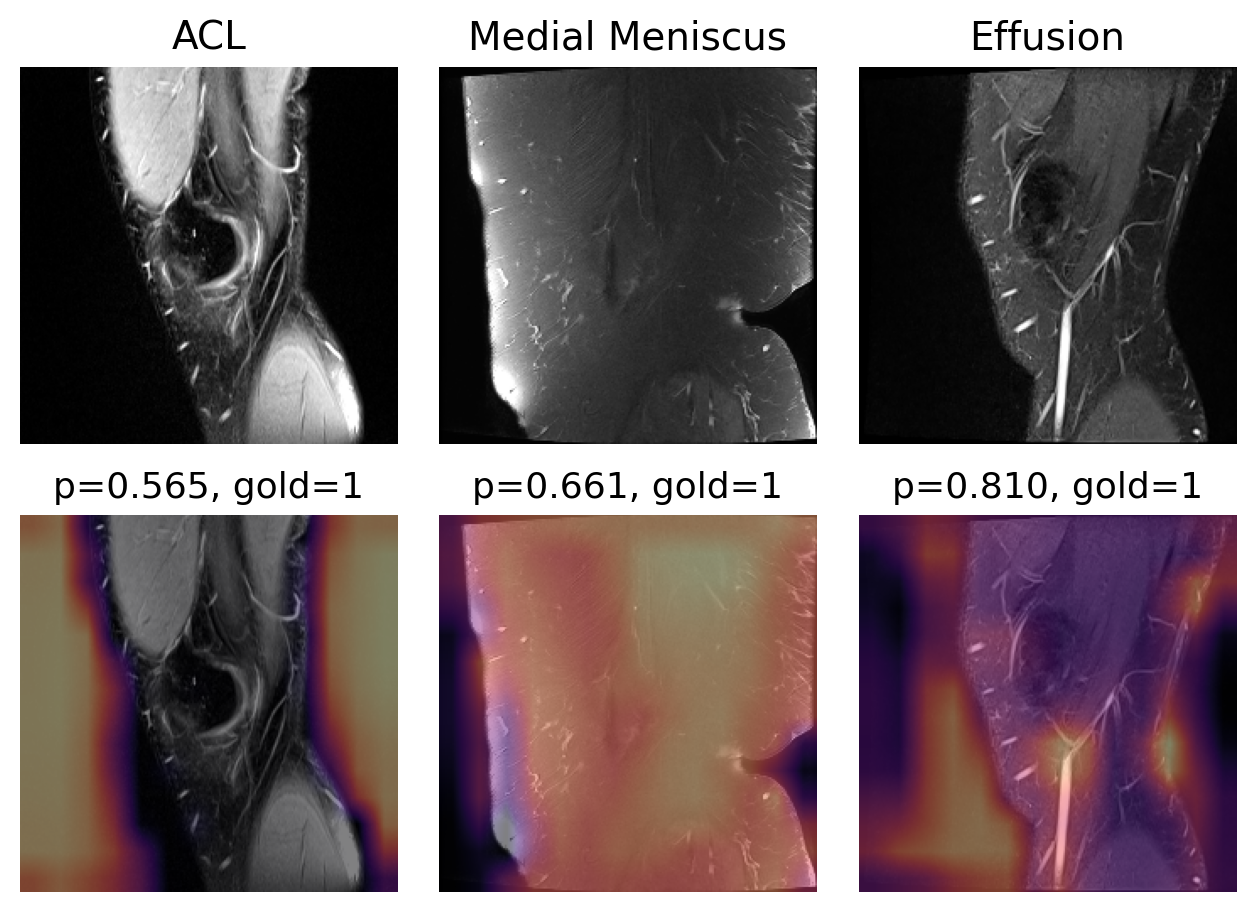

,label,label_index,study_id,series_id,selected_stack,probability,gold_target,selection,nonzero_fraction
0,ACL,0,1.2.826.0.1.3680043.8.498.11382021393803389951...,1.2.826.0.1.3680043.8.498.91903627435354016135...,7,0.564936,1,first gold-positive study; maximum mean normal...,0.673469
1,Medial Meniscus,2,1.2.826.0.1.3680043.8.498.10306159113324811538...,1.2.826.0.1.3680043.8.498.10903465965639594231...,0,0.661183,1,first gold-positive study; maximum mean normal...,0.998724
2,Effusion,7,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.37372672584387115708...,0,0.809833,1,first gold-positive study; maximum mean normal...,0.999841


In [7]:
figure_root = settings.output_root / 'reports/mri/figures'
for filename in ['auc_matrix.png', 'curves_scratch.png', 'curves_resnet50.png', 'cam_grid.png']:
    display(Image(filename=str(figure_root / filename), width=950))
display(pd.DataFrame(read_json(output / 'scratch_bce_weighted/cam_cases.json')))


## Informe y trazabilidad

Las tablas, figuras y PDF se generan desde métricas reales y auditadas. La configuración, hashes de código, pesos y checkpoints se conservan junto a los resultados. La entrega incorpora los cinco autores y revisión técnica/visual. La aprobación editorial del grupo y la entrega por la plataforma siguen pendientes; no se registra validación clínica profesional. Las métricas se recalculan desde predicciones persistidas, sin nueva inferencia.


In [8]:
if GENERATE_REPORT_ASSETS:
    display(prepare_report_assets(settings, task))


## Limitaciones y conclusiones

Una única semilla y 58 expertos limitan la precisión de la comparación. Si una etiqueta tiene solo una clase, su AUC y el macro oficial de doce etiquetas quedan indefinidos; el macro parcial se identifica por separado. Precisión, recall y F1 usan zero_division=0. El filtro de confianza se aplica por etiqueta y conserva 434 estudios de entrenamiento y 108 de validación. En sinovitis deja 140 etiquetas de entrenamiento, todas positivas, sin negativos explícitos. La cobertura de escritura no equivale a detección de idioma, procedencia o validación clínica. Los Grad-CAM son observaciones espaciales y no acreditan causalidad ni localización radiológica correcta.
